# 01 · Data Merge, Cleaning & EDA

**Owner:** Hassan Adelani · **Covers:** merge & cleaning, and EDA

This notebook builds `data/processed/merged_customer_data.csv`, the training data for the **Product Recommendation Model**, from two sources:

| File | Grain | Key |
|---|---|---|
| `customer_social_profiles.csv` | one row per customer **per social profile** | `customer_id_new` (string, e.g. `A178`) |
| `customer_transactions.csv` | one row per **transaction** | `customer_id_legacy` (integer, e.g. `178`) |

The cleaning, merge and feature logic lives in [`src/data_merge.py`](../src/data_merge.py), so the CLI app and training scripts can rerun it. This notebook calls those functions one step at a time and shows the evidence and reasoning behind each decision.

**Part 1: Merge & cleaning (1B)**
1. Load & inspect
2. Clean social profiles
3. Clean transactions
4. Aggregate social profiles per customer
5. Join (and why it is a LEFT join)
6. Post-merge validation
7. Feature engineering (leakage-safe)
8. Save & reload check

**Part 2: EDA (1C)**
9. Summary statistics & variable types
10. Target balance
11. Distributions
12. Outliers by category
13. Correlations
14. Categorical features vs. target
15. EDA takeaways for the product model

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config
from src import data_merge as dm

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load & inspect

In [2]:
social_raw, tx_raw = dm.load_raw()
print("social profiles:", social_raw.shape, "| transactions:", tx_raw.shape)
display(social_raw.head())
display(tx_raw.head())

social profiles: (155, 5) | transactions: (150, 6)


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


In [3]:
def profile(df: pd.DataFrame) -> pd.DataFrame:
    """Per-column dtype, null count and cardinality."""
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulls": df.isna().sum(),
        "null_%": (df.isna().mean() * 100).round(1),
        "unique": df.nunique(),
        "example": df.iloc[0],
    })

print("customer_social_profiles")
display(profile(social_raw))
print(f"exact duplicate rows: {social_raw.duplicated().sum()}")

print("\ncustomer_transactions")
display(profile(tx_raw))
print(f"exact duplicate rows: {tx_raw.duplicated().sum()} | "
      f"duplicate transaction_id: {tx_raw['transaction_id'].duplicated().sum()}")

customer_social_profiles


,dtype,nulls,null_%,unique,example
customer_id_new,str,0,0.0,84,A178
social_media_platform,str,0,0.0,5,LinkedIn
engagement_score,int64,0,0.0,50,74
purchase_interest_score,float64,0,0.0,40,4.9
review_sentiment,str,0,0.0,3,Positive


exact duplicate rows: 5

customer_transactions


,dtype,nulls,null_%,unique,example
customer_id_legacy,int64,0,0.0,75,151
transaction_id,int64,0,0.0,150,1001
purchase_amount,int64,0,0.0,120,408
purchase_date,str,0,0.0,150,2024-01-01
product_category,str,0,0.0,5,Sports
customer_rating,float64,10,6.7,37,2.3


exact duplicate rows: 0 | duplicate transaction_id: 0


In [4]:
display(social_raw.describe().T)
display(tx_raw.describe().T)

,count,mean,std,min,25%,50%,75%,max
engagement_score,155.0,75.606452,14.568021,50.0,63.50,77.0,87.5,99.0
purchase_interest_score,155.0,3.152903,1.142867,1.0,2.35,3.2,4.1,5.0


,count,mean,std,min,25%,50%,75%,max
customer_id_legacy,150.0,148.760,30.046425,100.0,121.25,150.5,174.75,199.0
transaction_id,150.0,1075.500,43.445368,1001.0,1038.25,1075.5,1112.75,1150.0
purchase_amount,150.0,280.780,121.329595,51.0,179.00,274.0,388.50,495.0
customer_rating,140.0,2.985,1.206990,1.0,1.95,3.0,4.00,5.0


In [5]:
# Problems to resolve before joining
dupes = social_raw[social_raw.duplicated(keep=False)].sort_values(list(social_raw.columns))
print("Exact duplicate profile rows (both copies shown):")
display(dupes)

social_ids = set(social_raw["customer_id_new"].str.lstrip("A").astype(int))
tx_ids = set(tx_raw["customer_id_legacy"])
profiles_per_customer = social_raw.drop_duplicates().groupby("customer_id_new").size()

print("Profiles per customer:", profiles_per_customer.value_counts().sort_index().to_dict())
print(f"Customers in transactions: {len(tx_ids)} | in social: {len(social_ids)} | in both: {len(tx_ids & social_ids)}")
print(f"Transaction customers WITHOUT a profile: {len(tx_ids - social_ids)} -> {sorted(tx_ids - social_ids)}")
print(f"Profile customers WITHOUT transactions: {len(social_ids - tx_ids)}")

Exact duplicate profile rows (both copies shown):


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
18,A116,Twitter,78,1.1,Negative
151,A116,Twitter,78,1.1,Negative
73,A125,LinkedIn,66,4.7,Positive
150,A125,LinkedIn,66,4.7,Positive
76,A155,TikTok,98,4.8,Positive
154,A155,TikTok,98,4.8,Positive
78,A162,Twitter,71,4.8,Positive
153,A162,Twitter,71,4.8,Positive
118,A189,Twitter,59,3.8,Neutral
152,A189,Twitter,59,3.8,Neutral


Profiles per customer: {1: 43, 2: 23, 3: 13, 4: 4, 6: 1}
Customers in transactions: 75 | in social: 84 | in both: 61
Transaction customers WITHOUT a profile: 14 -> [108, 110, 123, 134, 136, 153, 157, 159, 161, 164, 170, 171, 175, 184]
Profile customers WITHOUT transactions: 23


**What the inspection shows**

- **Different key formats:** `customer_id_new` is a string with an `A` prefix and `customer_id_legacy` is an integer. Both use the same 100–199 numbering, so stripping the `A` gives a common integer `customer_id`.
- **Social profiles are not one row per customer:** 41 of 84 customers have 2–6 profiles (customer 155 has 6). Joining raw profile rows to transactions would be **many-to-many** and duplicate transactions, so profiles must be aggregated first.
- **5 exact duplicate profile rows** (the last 5 lines of the file repeat earlier rows). These are data-entry duplicates and should be dropped.
- **`customer_rating` has 10 nulls** (6.7%). No other column has missing values.
- **Partial overlap:** 14 transaction customers have no social profile, and 23 profile customers have no transactions.
- `purchase_date` is stored as text and needs parsing.

## 2. Clean social profiles

Steps: strip and normalise text, drop exact duplicates, derive the integer key, and check that every value is in its valid domain (5 known platforms, 3 sentiments, engagement in 0–100, interest in 0–5).

In [6]:
social, social_report = dm.clean_social_profiles(social_raw)
display(pd.Series(social_report, name="social profiles").to_frame())
display(social.head())

,social profiles
rows_before,155
exact_duplicates_dropped,5
rows_after,150
nulls,0
unique_customers,84


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment,customer_id
0,A178,LinkedIn,74,4.9,Positive,178
1,A190,Twitter,82,4.8,Neutral,190
2,A150,Facebook,96,1.6,Positive,150
3,A162,Twitter,89,2.6,Positive,162
4,A197,Twitter,92,2.3,Neutral,197


## 3. Clean transactions

- **Types:** `purchase_date` → datetime, numeric columns cast, the key renamed to `customer_id`.
- **Keys:** `transaction_id` is checked for uniqueness.
- **Missing `customer_rating` (10 rows):** filled with the **customer's own median rating**. Rating behaviour is personal (some people rate harshly), so this is a closer guess than a global value. Customers with no other rated purchase fall back to the **global median**. A `rating_was_missing` flag records which values were imputed.
- **Outliers in `purchase_amount`:** checked with the IQR rule (values beyond Q1 − 1.5·IQR or Q3 + 1.5·IQR). Outliers are **flagged, not dropped**. With only 150 rows, a plausible large purchase is information, not noise.

In [7]:
tx, tx_report = dm.clean_transactions(tx_raw)
display(pd.Series(tx_report, name="transactions").to_frame())

imputed = tx[tx["rating_was_missing"] == 1][["transaction_id", "customer_id", "product_category", "customer_rating"]]
imputed = imputed.assign(
    customer_other_ratings=imputed["customer_id"].map(
        tx_raw.groupby("customer_id_legacy")["customer_rating"].apply(lambda s: s.dropna().tolist())
    )
)
print("Imputed ratings (an empty list means the global median was used):")
display(imputed)

,transactions
rows_before,150
exact_duplicates,0
duplicate_transaction_ids,0
missing_ratings,10
ratings_imputed_customer_median,6
ratings_imputed_global_median,4
global_rating_median,3.0
amount_iqr_bounds,"(-135.25, 702.75)"
amount_outliers,0
rows_after,150


Imputed ratings (an empty list means the global median was used):


,transaction_id,customer_id,product_category,customer_rating,customer_other_ratings
38,1039,161,Groceries,1.4,"[2.6, 1.2, 2.7, 1.4, 1.3]"
41,1042,150,Sports,3.6,[3.6]
42,1043,154,Electronics,3.0,[]
69,1070,135,Electronics,3.0,[]
80,1081,189,Books,3.1,"[3.2, 3.0]"
88,1089,147,Groceries,3.8,[3.8]
97,1098,181,Clothing,3.0,[]
100,1101,125,Electronics,3.0,[]
109,1110,170,Electronics,1.3,[1.3]
142,1143,198,Books,2.5,[2.5]


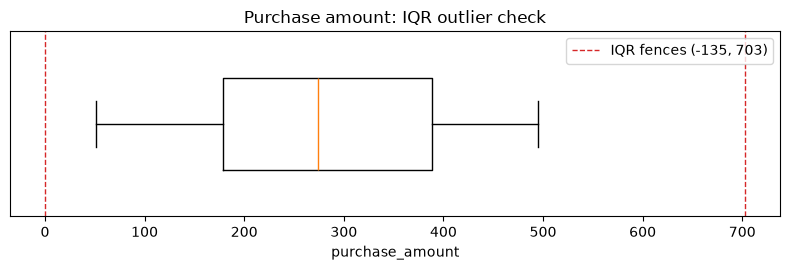

{'count': 150.0, 'mean': 280.8, 'std': 121.3, 'min': 51.0, '25%': 179.0, '50%': 274.0, '75%': 388.5, 'max': 495.0}


In [8]:
low, high = tx_report["amount_iqr_bounds"]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.boxplot(tx["purchase_amount"], orientation="horizontal", widths=0.5)
ax.axvline(max(low, 0), ls="--", c="tab:red", lw=1, label=f"IQR fences ({low:.0f}, {high:.0f})")
ax.axvline(high, ls="--", c="tab:red", lw=1)
ax.set_xlabel("purchase_amount")
ax.set_yticks([])
ax.set_title("Purchase amount: IQR outlier check")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "merge_purchase_amount_iqr.png", dpi=150)
plt.show()
print(tx["purchase_amount"].describe().round(1).to_dict())

**Interpretation:** every `purchase_amount` lies inside the IQR fences. Q1 = 179 and Q3 = 388.5, so the fences are −135 and 703, well past the observed range of 51–495. **No outliers are flagged.** Amounts are spread fairly evenly between 51 and 495 with no extreme tail. `amount_is_outlier` is kept as a column so the rule is documented and would catch outliers if new data were added.

## 4. Aggregate social profiles to one row per customer

The target lives at the transaction level, but social behaviour lives at the customer level. Each customer's profiles are summarised into fixed-width features:

| Feature | Meaning |
|---|---|
| `n_social_profiles`, `n_platforms` | how present the customer is on social media |
| `avg_/max_engagement` | engagement level across profiles |
| `avg_/max_purchase_interest` | stated purchase interest |
| `sentiment_score` | mean of Positive = +1, Neutral = 0, Negative = −1 |
| `pct_positive/neutral/negative` | sentiment mix |
| `plat_<Platform>` | number of profiles on each platform |
| `dominant_platform` | most frequent platform (ties → higher engagement) |

In [9]:
social_agg = dm.aggregate_social_profiles(social)
print(social_agg.shape, "-> one row per customer:", social_agg["customer_id"].is_unique)

example = 189
print(f"\nRaw profiles for customer {example}:")
display(social[social["customer_id"] == example])
print(f"Aggregated row for customer {example}:")
display(social_agg[social_agg["customer_id"] == example])

(84, 17) -> one row per customer: True

Raw profiles for customer 189:


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment,customer_id
64,A189,LinkedIn,78,2.7,Negative,189
69,A189,TikTok,99,4.1,Neutral,189
93,A189,Facebook,94,3.8,Negative,189
118,A189,Twitter,59,3.8,Neutral,189


Aggregated row for customer 189:


,customer_id,n_social_profiles,n_platforms,avg_engagement,max_engagement,avg_purchase_interest,max_purchase_interest,sentiment_score,plat_Facebook,plat_Instagram,plat_LinkedIn,plat_TikTok,plat_Twitter,pct_positive,pct_neutral,pct_negative,dominant_platform
73,189,4,4,82.5,99,3.6,4.1,-0.5,1,0,1,1,1,0.0,0.5,0.5,TikTok


## 5. Join strategy

Three possible joins:

In [10]:
many_to_many = tx.merge(social, on="customer_id", how="inner")
inner = tx.merge(social_agg, on="customer_id", how="inner")
left = tx.merge(social_agg, on="customer_id", how="left")

pd.DataFrame({
    "join": ["raw profiles INNER (many-to-many)", "aggregated INNER", "aggregated LEFT (chosen)"],
    "rows": [len(many_to_many), len(inner), len(left)],
    "unique transactions": [many_to_many["transaction_id"].nunique(), inner["transaction_id"].nunique(), left["transaction_id"].nunique()],
    "problem": ["transactions duplicated, so labels are double-counted",
                f"drops {len(tx) - len(inner)} transactions ({(len(tx) - len(inner)) / len(tx):.0%}) with no profile",
                "none: every transaction kept exactly once"],
})

,join,rows,unique transactions,problem
0,raw profiles INNER (many-to-many),213,117,"transactions duplicated, so labels are double-..."
1,aggregated INNER,117,117,drops 33 transactions (22%) with no profile
2,aggregated LEFT (chosen),150,150,none: every transaction kept exactly once


**Why aggregated LEFT join on `customer_id`:**

1. **The prediction unit is a transaction.** The model predicts `product_category`, so the merged table must have exactly one row per transaction. Aggregating profiles first makes the right side unique per customer, which turns the join into **many-to-one**. Pandas enforces this with `validate="many_to_one"`.
2. **No labelled data is thrown away.** An inner join would lose 33 of 150 transactions (22%) from a dataset that is already very small. The 23 profile-only customers have no purchases (no label), so they cannot be training rows either way.
3. **Missing profiles are handled explicitly:**
   - **Counts and shares → 0:** no profile means no observed activity.
   - **`sentiment_score` → 0:** treated as neutral.
   - **Engagement and interest levels → the median of customers who have profiles:** the level is unknown rather than zero.
   - **`has_social_profile`:** a 0/1 flag so the model can tell imputed rows from real ones.

In [11]:
null_before = left.isna().sum()
merged, merge_report = dm.merge_datasets(tx, social_agg)
null_after = merged.isna().sum()

nulls = pd.DataFrame({"nulls before imputation": null_before, "nulls after": null_after}).fillna(0).astype(int)
display(nulls[nulls.sum(axis=1) > 0])
display(pd.Series({k: v for k, v in merge_report.items() if k != "social_only_customers"}, name="merge").to_frame())

,nulls before imputation,nulls after
avg_engagement,33,0
avg_purchase_interest,33,0
dominant_platform,33,0
max_engagement,33,0
max_purchase_interest,33,0
n_platforms,33,0
n_social_profiles,33,0
pct_negative,33,0
pct_neutral,33,0
pct_positive,33,0


,merge
inner_join_rows,117
left_join_rows,150
matched_rows,117
unmatched_rows,33
unmatched_customers,"[108, 110, 123, 134, 136, 153, 157, 159, 161, ..."
nulls_before_imputation,528
nulls_after_imputation,0


## 6. Post-merge validation

The checks below are enforced in code: `validate_merge` raises an error if any of them fails.

In [12]:
checks = dm.validate_merge(merged, tx, social)
checks

,check,passed,detail
0,Row count preserved,True,150 merged vs 150 transactions
1,transaction_id unique,True,
2,Same transaction_id set,True,
3,No nulls after imputation,True,0 nulls
4,Target has no nulls,True,
5,Aggregates match source rows,True,0 mismatching customers
6,Unmatched customers truly lack profiles,True,


In [13]:
# Manual spot checks against the raw files:
#   187 = several transactions + several profiles
#   171 = transactions but no profile (imputed)
#   101 = several transactions + one profile
spot_cols = ["transaction_id", "customer_id", "product_category", "customer_rating",
             "has_social_profile", "n_social_profiles", "avg_engagement", "avg_purchase_interest",
             "sentiment_score", "dominant_platform"]
for cid in [187, 171, 101]:
    print(f"===== customer {cid} =====")
    print("raw profiles:")
    display(social_raw[social_raw["customer_id_new"] == f"A{cid}"])
    print("merged rows:")
    display(merged.loc[merged["customer_id"] == cid, spot_cols])

===== customer 187 =====
raw profiles:


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
8,A187,LinkedIn,97,4.4,Negative
22,A187,Instagram,71,2.5,Neutral
97,A187,Twitter,89,1.3,Negative


merged rows:


,transaction_id,customer_id,product_category,customer_rating,has_social_profile,n_social_profiles,avg_engagement,avg_purchase_interest,sentiment_score,dominant_platform
10,1011,187,Sports,1.7,1,3,85.666667,2.733333,-0.666667,LinkedIn
17,1018,187,Groceries,4.8,1,3,85.666667,2.733333,-0.666667,LinkedIn
111,1112,187,Sports,3.7,1,3,85.666667,2.733333,-0.666667,LinkedIn
114,1115,187,Sports,4.2,1,3,85.666667,2.733333,-0.666667,LinkedIn
134,1135,187,Books,4.9,1,3,85.666667,2.733333,-0.666667,LinkedIn


===== customer 171 =====
raw profiles:


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment


... (2 outputs left out)

===== customer 101 =====
raw profiles:


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
98,A101,Twitter,68,1.0,Neutral


merged rows:


,transaction_id,customer_id,product_category,customer_rating,has_social_profile,n_social_profiles,avg_engagement,avg_purchase_interest,sentiment_score,dominant_platform
16,1017,101,Books,2.1,1,1,68.0,1.0,0.0,Twitter
20,1021,101,Groceries,3.4,1,1,68.0,1.0,0.0,Twitter
58,1059,101,Books,2.5,1,1,68.0,1.0,0.0,Twitter
72,1073,101,Books,2.1,1,1,68.0,1.0,0.0,Twitter


**Spot-check result:**
- **Customer 187:** all 5 transactions are kept once each, and every row carries the same aggregated values. These equal the mean of the 3 raw profiles (engagement (97 + 71 + 89) / 3 = 85.67).
- **Customer 171:** `has_social_profile = 0`, counts are 0 and engagement/interest are imputed medians.
- **Customer 101:** the single profile's values pass through unchanged.

## 7. Feature engineering

**Date features:** `purchase_month`, `purchase_dayofweek`, `is_weekend`.

**Customer-history features (leakage-safe):** these are computed from each customer's **earlier** transactions only. Transactions are sorted by date and an expanding window is applied with a one-step shift. Each row therefore holds only what the system would know *before* that purchase, which matches the real use case: a returning customer visits and we predict their next purchase.

| Feature | Meaning |
|---|---|
| `cust_prev_txn_count` | number of earlier purchases |
| `is_first_purchase` | 1 if the customer has no history |
| `cust_prev_avg_amount`, `cust_prev_avg_rating` | average spend / rating on earlier purchases (first purchase → global median) |
| `days_since_prev_txn` | gap since the last purchase (−1 = first purchase) |
| `cust_prev_category` | most frequent earlier category, ties going to the most recent (`no_history` on the first purchase) |

**Leakage note for the product model:** `purchase_amount`, `amount_bucket` and `customer_rating` describe the purchase **being predicted**. A rating is given *after* buying, and the amount depends on what was bought. They stay in the dataset for EDA, but are listed in `dm.POST_PURCHASE_COLUMNS` so the model can exclude them in favour of the `cust_prev_*` features.

In [14]:
features = dm.engineer_features(merged)

timeline_cols = ["purchase_date", "transaction_id", "product_category", "purchase_amount",
                 "cust_prev_txn_count", "cust_prev_avg_amount", "days_since_prev_txn", "cust_prev_category"]
print("Customer 187 timeline: each row only 'sees' the rows above it")
features.loc[features["customer_id"] == 187, timeline_cols]

Customer 187 timeline: each row only 'sees' the rows above it


,purchase_date,transaction_id,product_category,purchase_amount,cust_prev_txn_count,cust_prev_avg_amount,days_since_prev_txn,cust_prev_category
10,2024-01-11,1011,Sports,401.0,0,274.000000,-1,no_history
17,2024-01-18,1018,Groceries,456.0,1,401.000000,7,Sports
111,2024-04-21,1112,Sports,233.0,2,428.500000,94,Groceries
114,2024-04-24,1115,Sports,304.0,3,363.333333,3,Sports
134,2024-05-14,1135,Books,469.0,4,348.500000,20,Sports


Reading the table: on 2024-04-21 customer 187 has 2 earlier purchases (401 and 456, so `cust_prev_avg_amount` = 428.5). The history is tied 1 Sports vs 1 Groceries, so the most recent category (Groceries) wins. The row's own category (Sports) is **never** used to build its own features.

## 8. Run the full pipeline, save and reload

In [15]:
final, reports = dm.build_merged_dataset(save=True, verbose=True)

reloaded = pd.read_csv(config.MERGED_CSV, parse_dates=["purchase_date"])
assert reloaded.shape == final.shape and reloaded.isna().sum().sum() == 0
print("\nReload check passed:", reloaded.shape)
reloaded.head()

Social profiles : 155 rows -> 150 after dropping 5 duplicates (84 customers)
Transactions    : 150 rows, 75 customers, 10 missing ratings imputed (6 customer median, 4 global median), 0 amount outliers flagged
Merge           : LEFT join 150 rows (117 matched / 33 without profile); INNER join would keep 117; 23 profile-only customers have no transactions (no label)
Validation      : 7/7 checks passed
Final dataset   : 150 rows x 35 columns, 0 nulls
Saved to        : data/processed/merged_customer_data.csv

Reload check passed: (150, 35)


,transaction_id,customer_id,purchase_date,product_category,purchase_amount,amount_bucket,amount_is_outlier,customer_rating,rating_was_missing,purchase_month,purchase_dayofweek,is_weekend,cust_prev_txn_count,is_first_purchase,cust_prev_avg_amount,cust_prev_avg_rating,days_since_prev_txn,cust_prev_category,has_social_profile,n_social_profiles,n_platforms,avg_engagement,max_engagement,avg_purchase_interest,max_purchase_interest,sentiment_score,pct_positive,pct_neutral,pct_negative,plat_Facebook,plat_Instagram,plat_LinkedIn,plat_TikTok,plat_Twitter,dominant_platform
0,1001,151,2024-01-01,Sports,408.0,high,0,2.3,0,1,0,0,0,1,274.0,3.0,-1,no_history,1,3,2,71.666667,82.0,2.166667,3.6,-0.333333,0.000000,0.666667,0.333333,0,0,0,1,2,Twitter
1,1002,192,2024-01-02,Electronics,332.0,medium,0,4.2,0,1,1,0,0,1,274.0,3.0,-1,no_history,1,1,1,60.000000,60.0,4.300000,4.3,1.000000,1.000000,0.000000,0.000000,0,1,0,0,0,Instagram
2,1003,114,2024-01-03,Electronics,442.0,high,0,2.1,0,1,2,0,0,1,274.0,3.0,-1,no_history,1,1,1,87.000000,87.0,4.800000,4.8,-1.000000,0.000000,0.000000,1.000000,1,0,0,0,0,Facebook
3,1004,171,2024-01-04,Clothing,256.0,medium,0,2.8,0,1,3,0,0,1,274.0,3.0,-1,no_history,0,0,0,75.833333,82.0,3.250000,3.8,0.000000,0.000000,0.000000,0.000000,0,0,0,0,0,no_profile
4,1005,160,2024-01-05,Clothing,64.0,low,0,1.3,0,1,4,0,0,1,274.0,3.0,-1,no_history,1,3,3,72.666667,89.0,2.500000,2.9,0.333333,0.333333,0.666667,0.000000,0,1,1,1,0,Instagram


In [16]:
groups = {
    "identifier": dm.ID_COLUMNS,
    "target": [dm.TARGET],
    "post-purchase (exclude from model)": dm.POST_PURCHASE_COLUMNS,
}
def group_of(col):
    for g, cols in groups.items():
        if col in cols:
            return g
    return "model feature"

pd.DataFrame({
    "column": reloaded.columns,
    "dtype": reloaded.dtypes.astype(str).values,
    "role": [group_of(c) for c in reloaded.columns],
    "unique": reloaded.nunique().values,
})

,column,dtype,role,unique
0,transaction_id,int64,identifier,150
1,customer_id,int64,identifier,75
2,purchase_date,datetime64[us],identifier,150
3,product_category,str,target,5
4,purchase_amount,float64,post-purchase (exclude from model),120
5,amount_bucket,str,post-purchase (exclude from model),3
6,amount_is_outlier,int64,model feature,1
7,customer_rating,float64,post-purchase (exclude from model),38
8,rating_was_missing,int64,post-purchase (exclude from model),2
9,purchase_month,int64,model feature,5


### Summary of Part 1 decisions

| Issue | Decision | Reason |
|---|---|---|
| Key format mismatch (`A178` vs `178`) | strip `A`, cast to int → `customer_id` | same numbering in both files |
| 5 duplicate profile rows | dropped | exact repeats add no information and bias aggregates |
| Several profiles per customer | aggregated to one row per customer | avoids a many-to-many join that duplicates transactions |
| 10 missing ratings | customer median → global median, plus `rating_was_missing` | ratings are personal; the flag keeps the imputation visible |
| `purchase_amount` outliers | IQR check, flag only (0 found) | no extreme values; every row is valuable at n = 150 |
| Join type | aggregated **LEFT** join on transactions | keeps all 150 labelled rows; inner would lose 22% |
| Missing profiles (33 rows) | zero counts / neutral sentiment / median levels, plus `has_social_profile` | absence of activity vs unknown level handled separately |
| Leakage | history features from prior transactions only; post-purchase columns listed | the model must only see what is known before the purchase |

**Output:** `data/processed/merged_customer_data.csv`, with 150 rows × 35 columns and 0 nulls.

---
# Part 2: Exploratory Data Analysis (Section 1C)

Every plot below is saved to `reports/figures/eda_*.png` for the report. Each one is followed by an interpretation.

**Plot conventions:** each product category keeps **the same colour in every chart** (Books = blue, Clothing = orange, Electronics = aqua, Groceries = yellow, Sports = pink). Category names always appear as axis labels or in a legend, so no chart depends on colour alone. Single-series charts use one neutral blue. The correlation heatmap uses a blue ↔ red diverging scale with grey at 0.

In [17]:
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

eda = pd.read_csv(config.MERGED_CSV, parse_dates=["purchase_date"])
T = dm.TARGET
CATS = dm.CATEGORIES  # fixed order -> fixed colour per category

# Colour palette validated for colour-vision deficiency (light mode)
CAT_COLORS = dict(zip(CATS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
SINGLE = "#2a78d6"
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
SEQUENTIAL = LinearSegmentedColormap.from_list("blue_seq", ["#f0efec", "#86b6ef", "#2a78d6", "#104281"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "legend.frameon": False, "font.size": 10,
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(config.FIGURES_DIR / f"eda_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 9. Summary statistics & variable types

In [18]:
role = {c: "identifier" for c in dm.ID_COLUMNS} | {T: "target"} | {c: "post-purchase" for c in dm.POST_PURCHASE_COLUMNS}

def kind(col):
    s = eda[col]
    if pd.api.types.is_datetime64_any_dtype(s):
        return "datetime"
    if s.dtype == object or pd.api.types.is_string_dtype(s):
        return "categorical (nominal)"
    if set(s.unique()) <= {0, 1}:
        return "binary"
    if col in {"purchase_month", "purchase_dayofweek", "cust_prev_txn_count", "n_social_profiles",
               "n_platforms", "days_since_prev_txn"} or col.startswith("plat_"):
        return "numeric (discrete)"
    return "numeric (continuous)"

var_types = pd.DataFrame({
    "pandas dtype": eda.dtypes.astype(str),
    "variable type": [kind(c) for c in eda.columns],
    "role": [role.get(c, "feature") for c in eda.columns],
    "unique": eda.nunique(),
})
display(var_types)
display(var_types.groupby(["variable type", "role"]).size().unstack(fill_value=0))

,pandas dtype,variable type,role,unique
transaction_id,int64,numeric (continuous),identifier,150
customer_id,int64,numeric (continuous),identifier,75
purchase_date,datetime64[us],datetime,identifier,150
product_category,str,categorical (nominal),target,5
purchase_amount,float64,numeric (continuous),post-purchase,120
amount_bucket,str,categorical (nominal),post-purchase,3
amount_is_outlier,int64,binary,feature,1
customer_rating,float64,numeric (continuous),post-purchase,38
rating_was_missing,int64,binary,post-purchase,2
purchase_month,int64,numeric (discrete),feature,5


role,feature,identifier,post-purchase,target
variable type,,,,
binary,4,0,1,0
categorical (nominal),2,0,1,1
datetime,0,1,0,0
numeric (continuous),10,2,2,0
numeric (discrete),11,0,0,0


In [19]:
key_numeric = ["purchase_amount", "customer_rating", "avg_engagement", "max_engagement",
               "avg_purchase_interest", "sentiment_score", "n_social_profiles",
               "cust_prev_txn_count", "cust_prev_avg_amount", "days_since_prev_txn"]
summary = eda[key_numeric].describe().T
summary["skew"] = eda[key_numeric].skew()
display(summary.round(2))

print("Categorical columns:")
for c in [T, "dominant_platform", "cust_prev_category", "amount_bucket"]:
    print(f"  {c:<20} {eda[c].value_counts().to_dict()}")
print(f"\nDate range: {eda['purchase_date'].min():%Y-%m-%d} to {eda['purchase_date'].max():%Y-%m-%d} "
      f"(one transaction per day)")
print("Transactions per customer:", eda.groupby("customer_id").size().value_counts().sort_index().to_dict())

,count,mean,std,min,25%,50%,75%,max,skew
purchase_amount,150.0,280.78,121.33,51.0,179.00,274.00,388.50,495.0,0.06
customer_rating,150.0,2.97,1.18,1.0,2.00,3.00,4.00,5.0,-0.07
avg_engagement,150.0,74.52,11.21,50.0,68.31,75.83,81.00,99.0,-0.47
max_engagement,150.0,80.65,14.02,50.0,77.00,82.00,92.00,99.0,-0.75
avg_purchase_interest,150.0,3.12,0.92,1.0,2.73,3.25,3.60,4.8,-0.48
sentiment_score,150.0,0.08,0.66,-1.0,-0.46,0.00,0.62,1.0,-0.11
n_social_profiles,150.0,1.42,1.09,0.0,1.00,1.00,2.00,4.0,0.44
cust_prev_txn_count,150.0,0.81,1.03,0.0,0.00,0.50,1.00,5.0,1.47
cust_prev_avg_amount,150.0,272.80,70.24,62.0,268.00,274.00,274.00,490.0,-0.01
days_since_prev_txn,150.0,17.93,27.46,-1.0,-1.00,0.00,31.75,109.0,1.48


Categorical columns:
  product_category     {'Sports': 35, 'Electronics': 34, 'Clothing': 28, 'Groceries': 28, 'Books': 25}
  dominant_platform    {'no_profile': 33, 'Twitter': 27, 'Facebook': 25, 'LinkedIn': 25, 'Instagram': 20, 'TikTok': 20}
  cust_prev_category   {'no_history': 75, 'Groceries': 21, 'Sports': 15, 'Electronics': 14, 'Books': 13, 'Clothing': 12}
  amount_bucket        {'high': 50, 'medium': 50, 'low': 50}

Date range: 2024-01-01 to 2024-05-29 (one transaction per day)
Transactions per customer: {1: 30, 2: 26, 3: 12, 4: 4, 5: 2, 6: 1}


**Interpretation**

- **Variable types:** the 35 columns are 3 identifiers, 1 nominal target, and a mix of continuous, discrete, binary and nominal features. The categorical features (`dominant_platform`, `cust_prev_category`, `amount_bucket`) need one-hot encoding before modelling.
- **Scales differ widely:** amounts run from 51 to 495, ratings from 1 to 5, and engagement from 50 to 99. Logistic Regression will need standardised features; tree models will not.
- **Skew is mild:** amount, rating, the averaged social scores and sentiment all have |skew| < 0.5, so no log transforms are needed. The exceptions are `max_engagement` (−0.75, bounded at 99), and `cust_prev_txn_count` and `days_since_prev_txn` (about 1.5). The last two are right-skewed because most customers have little history, and the −1 "first purchase" sentinel stacks up at the bottom.
- **The customer history is thin:** 30 of 75 customers bought only once, and **half of all transactions (75/150) are a customer's first purchase**, so they have no history. This limits how much the `cust_prev_*` features can help.

## 10. Target balance: `product_category`

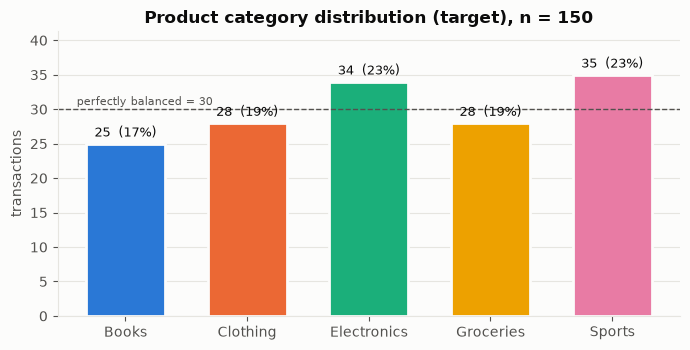

In [20]:
counts = eda[T].value_counts().reindex(CATS)
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(CATS, counts.values, color=[CAT_COLORS[c] for c in CATS], width=0.65,
              edgecolor=SURFACE, linewidth=2)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.6, f"{v}  ({v / len(eda):.0%})",
            ha="center", va="bottom", fontsize=9, color=INK)
ax.axhline(len(eda) / len(CATS), ls="--", lw=1, color=INK_2)
ax.text(-0.4, len(eda) / len(CATS) + 0.6, "perfectly balanced = 30", ha="left", fontsize=8, color=INK_2)
ax.set_ylabel("transactions")
ax.set_title("Product category distribution (target), n = 150")
ax.set_ylim(0, counts.max() * 1.18)
ax.grid(axis="x", visible=False)
save(fig, "target_balance")

**Interpretation:** the target is **close to balanced**. Sports (35, 23%) and Electronics (34, 23%) are slightly over-represented, and Books (25, 17%) is the smallest class, a max/min ratio of only 1.4. Resampling is not needed, but:
- the product model should use a **stratified** train/test split and stratified CV, so every fold keeps these proportions;
- **macro F1** is a fair headline metric, because no class dominates;
- the **majority-class baseline is 23.3%** accuracy (always predicting Sports), and random guessing gives 20%. The model must beat these to show it learned something.

## 11. Distributions

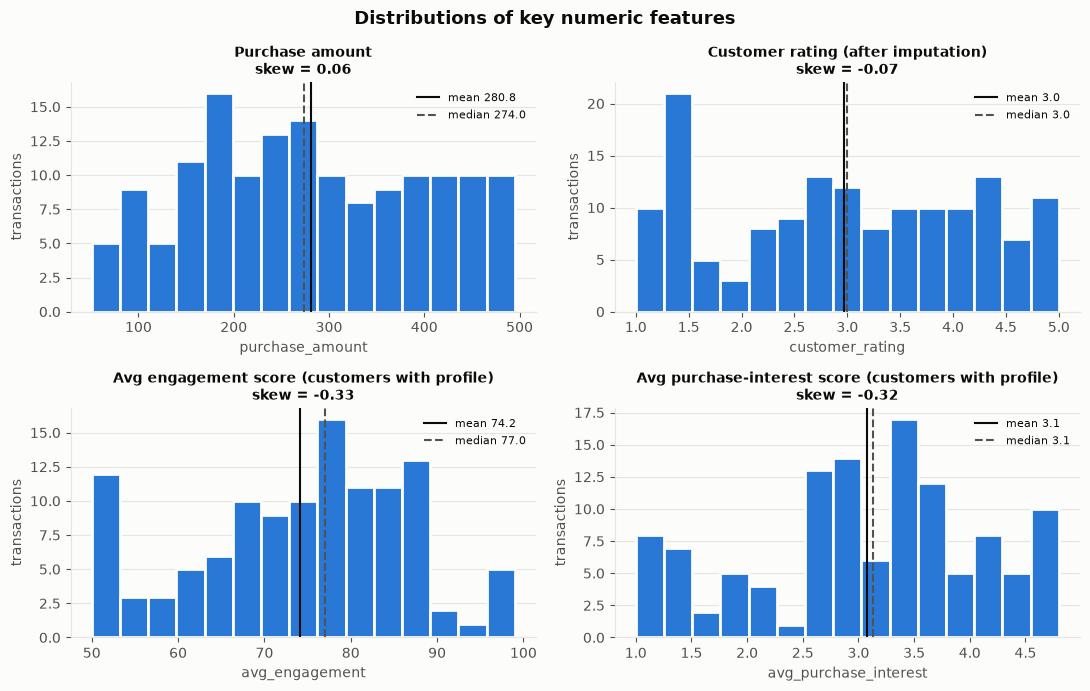

In [21]:
dist_cols = [
    ("purchase_amount", "Purchase amount", eda),
    ("customer_rating", "Customer rating (after imputation)", eda),
    ("avg_engagement", "Avg engagement score (customers with profile)", eda[eda["has_social_profile"] == 1]),
    ("avg_purchase_interest", "Avg purchase-interest score (customers with profile)", eda[eda["has_social_profile"] == 1]),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (col, title, src) in zip(axes.ravel(), dist_cols):
    vals = src[col]
    ax.hist(vals, bins=15, color=SINGLE, edgecolor=SURFACE, linewidth=2)
    ax.axvline(vals.mean(), color=INK, lw=1.5, label=f"mean {vals.mean():.1f}")
    ax.axvline(vals.median(), color=INK_2, lw=1.5, ls="--", label=f"median {vals.median():.1f}")
    ax.set_title(f"{title}\nskew = {vals.skew():.2f}", fontsize=10)
    ax.set_xlabel(col)
    ax.set_ylabel("transactions")
    ax.grid(axis="x", visible=False)
    ax.legend(fontsize=8, loc="upper right")
fig.suptitle("Distributions of key numeric features", fontsize=13, fontweight="bold")
save(fig, "distributions")

**Interpretation**

- **`purchase_amount`** is spread **roughly uniformly** between 51 and 495 (mean 281, median 274, skew 0.06). There is no long tail of big spenders.
- **`customer_rating`** is also spread across the whole 1–5 scale (mean and median 3.0). The only cluster is at very low ratings (about 1.1–1.4). Only 10 values are imputed (4 at the global median of 3.0, the rest at customer medians from 1.3 to 3.8), which is too few to create an artificial peak. Real review data usually piles up at 4–5 stars, so this flat shape suggests the dataset is **synthetic**.
- **Engagement and purchase interest** (customers with profiles only, so the imputed medians don't distort the shape) are mildly **left-skewed** (skew about −0.3). The mean sits slightly below the median (engagement 74.2 vs 77.0), pulled down by a group of low-engagement customers around 50.
- **Overall:** all features are bounded and roughly symmetric with no transformation needed. The flat, uniform shapes are an early warning that these features may carry **little signal** about the category.

## 12. Outliers by category

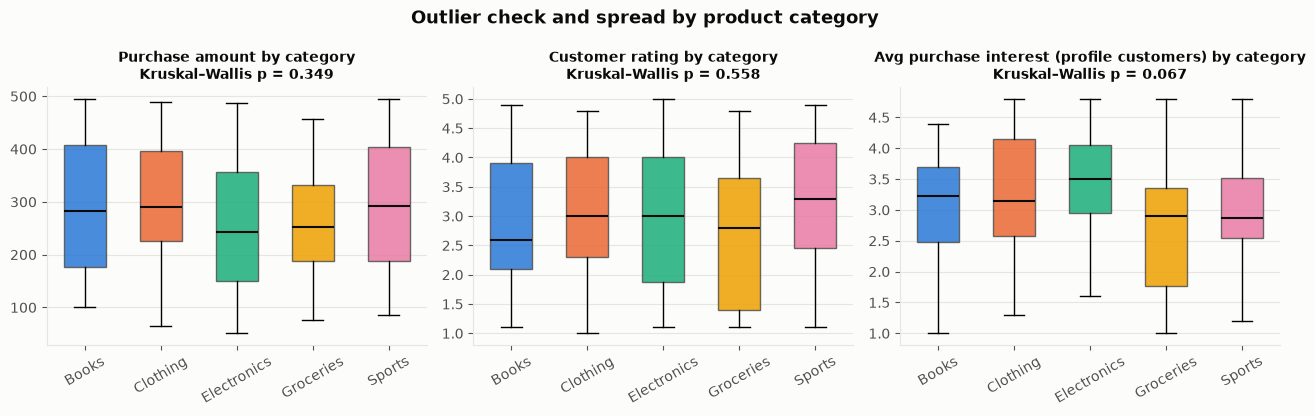

Global IQR fences for purchase_amount: [-135.2, 702.8] -> outliers: 0
purchase_amount          within-category IQR outliers: 0
customer_rating          within-category IQR outliers: 0
avg_purchase_interest    within-category IQR outliers: 0

For comparison, avg_purchase_interest INCLUDING the 33 imputed rows: 19 'outliers' (33 rows share the imputed value 3.25)


In [22]:
# Social features are plotted for customers WITH a profile only: the 33 imputed
# rows all share one median value (3.25), which would squeeze each box and make
# real values look like outliers.
profiled = eda[eda["has_social_profile"] == 1]
box_cols = [("purchase_amount", "Purchase amount", eda), ("customer_rating", "Customer rating", eda),
            ("avg_purchase_interest", "Avg purchase interest (profile customers)", profiled)]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (col, title, src) in zip(axes, box_cols):
    groups = [src.loc[src[T] == c, col] for c in CATS]
    bp = ax.boxplot(groups, tick_labels=CATS, patch_artist=True, widths=0.55,
                    medianprops={"color": INK, "lw": 1.5},
                    flierprops={"marker": "o", "markersize": 5, "markerfacecolor": INK_2, "markeredgecolor": SURFACE})
    for patch, c in zip(bp["boxes"], CATS):
        patch.set_facecolor(CAT_COLORS[c]); patch.set_alpha(0.85); patch.set_edgecolor(INK_2)
    p = stats.kruskal(*groups).pvalue
    ax.set_title(f"{title} by category\nKruskal–Wallis p = {p:.3f}", fontsize=10)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="x", visible=False)
fig.suptitle("Outlier check and spread by product category", fontsize=13, fontweight="bold")
save(fig, "outliers_by_category")

low, high = dm.iqr_bounds(eda["purchase_amount"])
print(f"Global IQR fences for purchase_amount: [{low:.1f}, {high:.1f}] -> outliers: {int(eda['amount_is_outlier'].sum())}")
def within_category_outliers(src, col):
    return sum(((g < lo) | (g > hi)).sum()
               for g in (src.loc[src[T] == c, col] for c in CATS)
               for lo, hi in [dm.iqr_bounds(g)])

for col, _, src in box_cols:
    print(f"{col:<24} within-category IQR outliers: {within_category_outliers(src, col)}")
print("\nFor comparison, avg_purchase_interest INCLUDING the 33 imputed rows: "
      f"{within_category_outliers(eda, 'avg_purchase_interest')} 'outliers' "
      f"({(eda['avg_purchase_interest'] == eda['avg_purchase_interest'].mode()[0]).sum()} rows share the imputed value "
      f"{eda['avg_purchase_interest'].mode()[0]})")

**Interpretation**

- **Outliers:** there are **no points beyond the whiskers** in any panel, globally or within any category, which confirms the decision in Part 1 to drop nothing.
- **An imputation artifact:** the interest panel uses customers with profiles only. With the 33 imputed rows included, the IQR rule flags **19 "outliers"** that are really normal values. All 33 imputed rows share one median value (3.25), which squeezes each category's box. This shows why the `has_social_profile` flag matters: analysis or models that treat imputed values as real observations can be misled.
- **Differences between categories are small:** median spend ranges from about 243 (Electronics) to about 292 (Sports), and every box overlaps heavily. Kruskal–Wallis (a rank test that doesn't assume normality) finds **no significant difference** in amount (p = 0.35) or rating (p = 0.56). Purchase interest is borderline (p ≈ 0.07): Electronics buyers have the highest median interest (3.5), and Sports and Groceries buyers the lowest (about 2.9).
- **Implication:** no single numeric feature separates the categories. The model will have to combine many weak signals, so accuracy should be expected to be modest.

## 13. Correlations

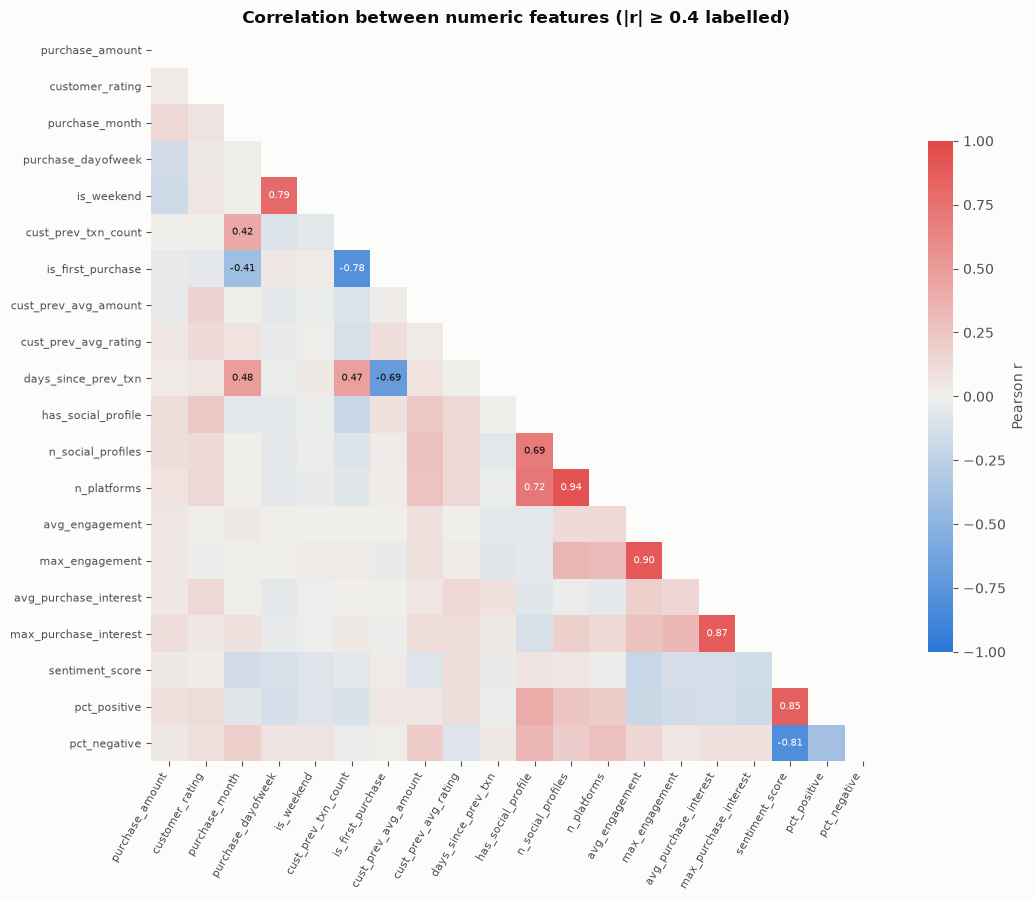

Strongly correlated pairs (|r| >= 0.7):


,,r
n_platforms,n_social_profiles,0.94
max_engagement,avg_engagement,0.90
max_purchase_interest,avg_purchase_interest,0.87
pct_positive,sentiment_score,0.85
pct_negative,sentiment_score,-0.81
is_weekend,purchase_dayofweek,0.79
is_first_purchase,cust_prev_txn_count,-0.78
n_platforms,has_social_profile,0.72


In [23]:
corr_cols = ["purchase_amount", "customer_rating", "purchase_month", "purchase_dayofweek", "is_weekend",
             "cust_prev_txn_count", "is_first_purchase", "cust_prev_avg_amount", "cust_prev_avg_rating",
             "days_since_prev_txn", "has_social_profile", "n_social_profiles", "n_platforms",
             "avg_engagement", "max_engagement", "avg_purchase_interest", "max_purchase_interest",
             "sentiment_score", "pct_positive", "pct_negative"]
corr = eda[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr.mask(mask), cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr_cols)), corr_cols, fontsize=8)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(corr_cols)):
    for j in range(i):
        r = corr.iat[i, j]
        if abs(r) >= 0.4:  # label only the notable cells
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(r) > 0.7 else INK)
cbar = fig.colorbar(im, ax=ax, shrink=0.7, label="Pearson r")
cbar.outline.set_visible(False)
ax.set_title("Correlation between numeric features (|r| ≥ 0.4 labelled)")
save(fig, "correlation_heatmap")

pairs = corr.where(np.tril(np.ones_like(corr, dtype=bool), -1)).stack()
strong = pairs[pairs.abs() >= 0.7].sort_values(key=abs, ascending=False)
print("Strongly correlated pairs (|r| >= 0.7):")
display(strong.round(2).rename("r").to_frame())

**Interpretation**

- **Redundant engineered features (|r| ≥ 0.85):**
  - `n_social_profiles` ↔ `n_platforms` (0.94)
  - `avg_engagement` ↔ `max_engagement` (0.90)
  - `avg_purchase_interest` ↔ `max_purchase_interest` (0.87)
  - `sentiment_score` ↔ `pct_positive` / `pct_negative` (0.85 / −0.81)

  This is expected, since each pair summarises the same profiles. For **Logistic Regression**, keep one feature per group (avg_*, n_social_profiles, sentiment_score) to avoid unstable coefficients. Tree models can keep all of them.
- **Correlated by construction:** `is_weekend` ↔ `purchase_dayofweek` (0.79) and `is_first_purchase` ↔ `cust_prev_txn_count` (−0.78). These are flags derived from the same variable.
- **The original features are almost independent:** purchase amount, rating, engagement and interest barely correlate with each other (e.g. rating ↔ amount r = 0.03). Each one brings separate (if weak) information, and none is a proxy for another.

## 14. Categorical features vs. target

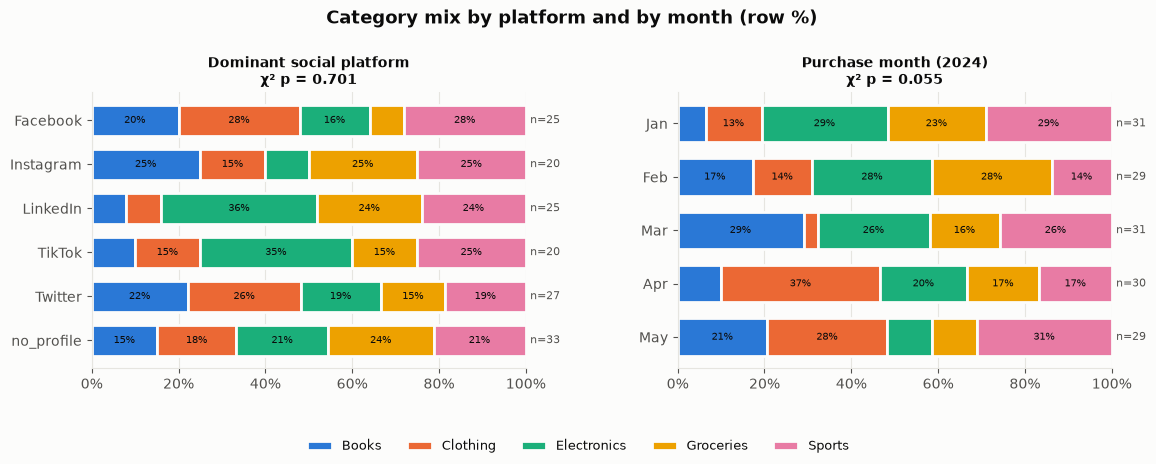

In [24]:
def row_share(col, order=None):
    ct = pd.crosstab(eda[col], eda[T]).reindex(columns=CATS)
    if order is not None:
        ct = ct.reindex(order)
    return ct, ct.div(ct.sum(axis=1), axis=0)

panels = [
    ("dominant_platform", "Dominant social platform", dm.PLATFORMS + [dm.NO_PROFILE]),
    ("purchase_month", "Purchase month (2024)", [1, 2, 3, 4, 5]),
]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"wspace": 0.35})
for ax, (col, title, order) in zip(axes, panels):
    ct, share = row_share(col, order)
    left = np.zeros(len(share))
    labels = [str(i) if col != "purchase_month" else pd.Timestamp(2024, i, 1).strftime("%b") for i in share.index]
    for c in CATS:
        ax.barh(labels, share[c], left=left, color=CAT_COLORS[c], edgecolor=SURFACE, linewidth=2, label=c, height=0.7)
        for y, (l, v) in enumerate(zip(left, share[c])):
            if v >= 0.12:
                ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=7.5, color=INK)
        left += share[c].values
    for y, n in enumerate(ct.sum(axis=1)):
        ax.text(1.01, y, f"n={n}", va="center", fontsize=8, color=INK_2)
    p = stats.chi2_contingency(ct).pvalue
    ax.set_title(f"{title}\nχ² p = {p:.3f}", fontsize=10)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", visible=False)
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle("Category mix by platform and by month (row %)", fontsize=13, fontweight="bold")
fig.subplots_adjust(left=0.1, right=0.95, top=0.8, bottom=0.2)
fig.legend(handles, labels, ncols=5, loc="lower center", fontsize=9)
fig.savefig(config.FIGURES_DIR / "eda_category_by_platform_month.png", dpi=150, bbox_inches="tight")
plt.show()

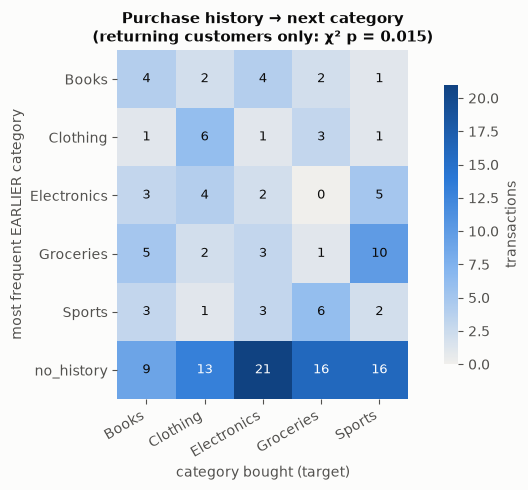

Returning-customer transactions: 75 | bought the SAME category as their usual one: 20%


product_category,Books,Clothing,Electronics,Groceries,Sports
dominant_platform,,,,,
Facebook,5,7,4,2,7
Instagram,5,3,2,5,5
LinkedIn,2,2,9,6,6
TikTok,2,3,7,3,5
Twitter,6,7,5,4,5
no_profile,5,6,7,8,7


In [25]:
trans = pd.crosstab(eda["cust_prev_category"], eda[T]).reindex(index=CATS + [dm.NO_HISTORY], columns=CATS)
fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(trans.values, cmap=SEQUENTIAL)
ax.set_xticks(range(len(CATS)), CATS, rotation=30, ha="right")
ax.set_yticks(range(len(trans.index)), trans.index)
ax.set_xlabel("category bought (target)")
ax.set_ylabel("most frequent EARLIER category")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(trans.shape[0]):
    for j in range(trans.shape[1]):
        v = trans.iat[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=9, color="white" if v > trans.values.max() * 0.6 else INK)
cbar = fig.colorbar(im, ax=ax, shrink=0.8, label="transactions")
cbar.outline.set_visible(False)
returning = eda[eda["cust_prev_category"] != dm.NO_HISTORY]
p = stats.chi2_contingency(trans.loc[CATS]).pvalue
ax.set_title(f"Purchase history → next category\n(returning customers only: χ² p = {p:.3f})", fontsize=11)
save(fig, "prev_category_transition")

repeat = (returning["cust_prev_category"] == returning[T]).mean()
print(f"Returning-customer transactions: {len(returning)} | bought the SAME category as their usual one: {repeat:.0%}")
display(pd.crosstab(eda["dominant_platform"], eda[T]).reindex(columns=CATS))

**Interpretation**

- **Platform:** LinkedIn- and TikTok-dominant customers buy more Electronics (35–36% vs 16–19% elsewhere), but overall the mix is not significantly different across platforms (χ² p ≈ 0.70, with only 20–27 transactions per platform). Customers without a profile (`no_profile`) buy the same mix as everyone else (χ² p ≈ 0.93 for `has_social_profile`). This also shows the left join's imputed rows are not a biased subgroup.
- **Month:** this is the clearest pattern. **April is dominated by Clothing (11 of 30)**, and January leans towards Electronics and Sports. Seasonality is borderline significant (χ² p ≈ 0.055), so `purchase_month` is worth keeping.
- **Purchase history:** returning customers buy their usual category again only **20%** of the time, the same as chance. Previous category still matters, but as a **transition**, not a repeat. For example, customers whose history is mostly *Groceries* bought *Sports* next 10 times out of 21. This association is significant (χ² p = 0.015), but several cells hold 0–2 transactions, so the χ² approximation is rough and the pattern may not generalise.
- These count tables are shown under the plots so every value can be read without relying on colour.

## 15. EDA takeaways for the product recommendation model

| Finding | Consequence for modelling |
|---|---|
| Target is near-balanced (17–23% per class) | Stratified split/CV; report macro F1; baseline = 23.3% (majority) and 20% (random) |
| No numeric feature separates categories on its own (Kruskal p > 0.05) | Expect modest accuracy; compare several models; tree ensembles may combine weak signals better |
| `purchase_month` and `cust_prev_category` show the strongest association | Keep them, one-hot encoded; they are the most promising features |
| Redundant pairs with \|r\| ≥ 0.85 | Keep one feature per group for Logistic Regression; trees can keep all |
| Half of all transactions have no history | `is_first_purchase` must stay so the model can discount imputed history values |
| Customers without a profile behave like the rest | The LEFT join + imputation is safe; `has_social_profile` is kept as a control |
| All features bounded, roughly symmetric, no outliers | Standardise for LR; no transforms or outlier removal needed |
| `purchase_amount` / `customer_rating` are post-purchase | Exclude from the model (see Part 1 §7); use the `cust_prev_*` versions instead |